# Lab 8: Decision Trees and Support Vector Machines


## Part A - Decision Tree from Scratch

###  Dataset Loading and Exploration

In [2]:
# Import libraries for data handling, numerical operations and visualization

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a random seed so that any random operations are reproducible
np.random.seed(42)

# Column names provided for the Banknote Authentication dataset
columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

# Load the dataset directly from the UCI repository
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00267/data_banknote_authentication.txt"
)

df = pd.read_csv(url, header=None, names=columns)

# Display the first five rows
display(df.head())

# Check the dimensions of the dataset
print("Dataset shape:", df.shape)

# Check data types and missing values
print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

# Examine the distribution of the target classes
print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

print("\nClass proportions:")
print(df["class"].value_counts(normalize=True).sort_index().round(3))

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Dataset shape: (1372, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing values in each column:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Class proportions:
class
0    0.555
1    0.445
Name: proportion, dtype: float64


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


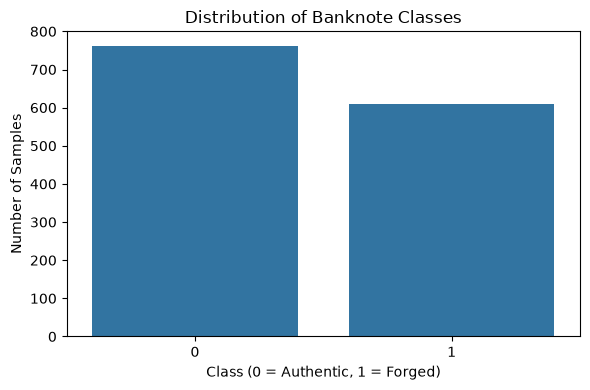

In [3]:
# Display summary statistics for the four input features
display(df.describe())

# Plot the number of authentic and forged banknotes
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="class")

plt.title("Distribution of Banknote Classes")
plt.xlabel("Class (0 = Authentic, 1 = Forged)")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


**Observations**

The dataset contains four numerical input features and one binary target variable. The summary statistics help identify the range and spread of each feature, while the class distribution plot shows whether the dataset is balanced.

These checks are useful before training a classifier because the feature ranges influence how we interpret the data, and class imbalance can affect the evaluation metrics.


### Splitting the Dataset

In [4]:
# Separate the input features and target variable
X = df.drop(columns="class")
y = df["class"]

# Import the function needed to split the dataset
from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training feature shape: (1097, 4)
Testing feature shape: (275, 4)

Training class distribution:
class
0    0.555
1    0.445
Name: proportion, dtype: float64

Testing class distribution:
class
0    0.556
1    0.444
Name: proportion, dtype: float64


**Observations**

The class proportions in the training and testing sets are almost identical. This makes the split suitable for evaluating the model without introducing a substantial difference in class distribution between the two sets.

### Implementing Impurity Measures

In [5]:
# Calculate Gini impurity for a set of class labels
def gini_impurity(y):
    # An empty node has no impurity
    if len(y) == 0:
        return 0.0

    # Find the proportion of samples belonging to each class
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    # Gini impurity is one minus the sum of squared probabilities
    return 1.0 - np.sum(probabilities ** 2)


# Calculate entropy for a set of class labels
def entropy(y):
    # An empty node has no entropy
    if len(y) == 0:
        return 0.0

    # Calculate the probability of each class
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    # Ignore zero probabilities to avoid log2(0)
    probabilities = probabilities[probabilities > 0]

    # Calculate entropy in bits
    return -np.sum(probabilities * np.log2(probabilities))

In [6]:
# Example 1: A completely mixed node
mixed_labels = np.array([0, 0, 1, 1])

# Example 2: A pure node containing only class 0
pure_labels = np.array([0, 0, 0, 0])

print("Mixed node:")
print("Gini impurity:", gini_impurity(mixed_labels))
print("Entropy:", entropy(mixed_labels))

print("\nPure node:")
print("Gini impurity:", gini_impurity(pure_labels))
print("Entropy:", entropy(pure_labels))

# Calculate impurity at the root of our actual training set
print("\nBanknote training set:")
print("Gini impurity:", round(gini_impurity(y_train), 4))
print("Entropy:", round(entropy(y_train), 4))

Mixed node:
Gini impurity: 0.5
Entropy: 1.0

Pure node:
Gini impurity: 0.0
Entropy: -0.0

Banknote training set:
Gini impurity: 0.4939
Entropy: 0.9912


**Observations**

| Test case | Gini impurity | Entropy |
|---|---:|---:|
| Mixed node | 0.5 | 1.0 |
| Pure node | 0.0 | 0.0 |
| Banknote training set | 0.4939 | 0.9912 |


The mixed node has the maximum impurity for a binary classification problem with equally represented classes. The pure node has zero impurity because all samples belong to the same class.

For the banknote training set, Gini impurity is 0.4939 and entropy is 0.9912. These values indicate that both classes are well represented at the root node.

Both measures can be used to select Decision Tree splits. In the next step, I will use these functions to evaluate candidate feature-threshold splits and identify the split that produces the greatest reduction in impurity.

### Find the best split

In [7]:
# Calculate the weighted impurity after a proposed split
def weighted_impurity(y_left, y_right, criterion="gini"):
    # Choose the impurity measure
    if criterion == "gini":
        impurity_function = gini_impurity
    elif criterion == "entropy":
        impurity_function = entropy
    else:
        raise ValueError("Criterion must be 'gini' or 'entropy'.")

    # Total number of samples in both child nodes
    total_samples = len(y_left) + len(y_right)

    # A valid split must have samples on both sides
    if len(y_left) == 0 or len(y_right) == 0:
        return float("inf")

    # Weight each child's impurity by its proportion of samples
    left_weight = len(y_left) / total_samples
    right_weight = len(y_right) / total_samples

    return (
        left_weight * impurity_function(y_left)
        + right_weight * impurity_function(y_right)
    )

In [8]:
# Search all features and candidate thresholds for the best split
def find_best_split(X, y, criterion="gini"):
    # Measure the impurity before splitting
    if criterion == "gini":
        parent_impurity = gini_impurity(y)
    elif criterion == "entropy":
        parent_impurity = entropy(y)
    else:
        raise ValueError("Criterion must be 'gini' or 'entropy'.")

    best_split = None
    best_impurity = float("inf")

    # Examine one feature at a time
    for feature in X.columns:
        values = np.sort(X[feature].unique())

        # Midpoints between consecutive unique values are candidate thresholds
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            # Divide the samples using the current rule
            left_mask = X[feature] <= threshold
            right_mask = ~left_mask

            # Skip splits that leave a child empty
            if not left_mask.any() or not right_mask.any():
                continue

            y_left = y.loc[left_mask]
            y_right = y.loc[right_mask]

            # Calculate the impurity of the two child nodes
            current_impurity = weighted_impurity(
                y_left,
                y_right,
                criterion=criterion
            )

            # Keep the split with the lowest weighted impurity
            if current_impurity < best_impurity:
                best_impurity = current_impurity
                best_split = {
                    "feature": feature,
                    "threshold": float(threshold),
                    "weighted_impurity": float(current_impurity),
                    "impurity_reduction": float(
                        parent_impurity - current_impurity
                    )
                }

    return best_split

In [9]:
# Find the best root split using Gini impurity
best_gini_split = find_best_split(
    X_train,
    y_train,
    criterion="gini"
)

print("Best split using Gini impurity:")
print(best_gini_split)

# Find the best root split using entropy
best_entropy_split = find_best_split(
    X_train,
    y_train,
    criterion="entropy"
)

print("\nBest split using entropy:")
print(best_entropy_split)

Best split using Gini impurity:
{'feature': 'variance', 'threshold': 0.7651, 'weighted_impurity': 0.25182235494123956, 'impurity_reduction': 0.24209450956617234}

Best split using entropy:
{'feature': 'variance', 'threshold': 0.7651, 'weighted_impurity': 0.5884013822087819, 'impurity_reduction': 0.40280462579181764}


*** Observations ***

The best split selected by both Gini impurity and entropy uses the variance feature with a threshold of 0.7651.

| Criterion | Selected feature | Threshold | Weighted impurity | Impurity reduction |
|---|---|---:|---:|---:|
| Gini | variance | 0.7651 | 0.2518 | 0.2421 |
| Entropy | variance | 0.7651 | 0.5884 | 0.4028 |

Both criteria selected the same feature and threshold for the root node. However, their weighted impurity values differ because Gini impurity and entropy use different mathematical definitions.

The impurity reduction measures the improvement achieved by splitting the parent node. A larger reduction indicates a greater decrease in impurity according to the selected criterion.

This function will serve as the basis for recursively constructing the Decision Tree.


### Build the Decision Tree recursively

In [10]:
# Build the tree recursively using the best available split
def build_tree(X, y, criterion="gini", max_depth=5,
               min_samples_split=2, min_samples_leaf=1, depth=0):

    # The majority class becomes the default prediction for this node
    classes, counts = np.unique(y, return_counts=True)
    majority_class = classes[np.argmax(counts)]

    # Stop if the node is pure or a stopping condition is reached
    if (
        len(classes) == 1
        or depth >= max_depth
        or len(y) < min_samples_split
        or len(y) < 2 * min_samples_leaf
    ):
        return {
            "leaf": True,
            "prediction": majority_class,
            "samples": len(y),
            "class_counts": dict(zip(classes.tolist(), counts.tolist()))
        }

    # Find the best split for the current node
    split = find_best_split(X, y, criterion=criterion)

    # Stop if no valid split can be found
    if split is None:
        return {
            "leaf": True,
            "prediction": majority_class,
            "samples": len(y),
            "class_counts": dict(zip(classes.tolist(), counts.tolist()))
        }

    feature = split["feature"]
    threshold = split["threshold"]

    # Divide the feature data and labels using the selected rule
    left_mask = X[feature] <= threshold
    right_mask = ~left_mask

    # Do not create a split that produces undersized child nodes
    if (
        left_mask.sum() < min_samples_leaf
        or right_mask.sum() < min_samples_leaf
    ):
        return {
            "leaf": True,
            "prediction": majority_class,
            "samples": len(y),
            "class_counts": dict(zip(classes.tolist(), counts.tolist()))
        }

    # Construct the left and right subtrees
    left_subtree = build_tree(
        X.loc[left_mask],
        y.loc[left_mask],
        criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        depth=depth + 1
    )

    right_subtree = build_tree(
        X.loc[right_mask],
        y.loc[right_mask],
        criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        depth=depth + 1
    )

    # Store the split rule and its child subtrees
    return {
        "leaf": False,
        "feature": feature,
        "threshold": threshold,
        "prediction": majority_class,
        "samples": len(y),
        "impurity_reduction": split["impurity_reduction"],
        "left": left_subtree,
        "right": right_subtree
    }

In [11]:
# Train a manual Decision Tree using the training set
manual_tree = build_tree(
    X_train,
    y_train,
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

print("Manual Decision Tree trained successfully.")
print("Root feature:", manual_tree["feature"])
print("Root threshold:", manual_tree["threshold"])
print("Root impurity reduction:", manual_tree["impurity_reduction"])

Manual Decision Tree trained successfully.
Root feature: variance
Root threshold: 0.7651
Root impurity reduction: 0.24209450956617234


In [12]:
# Predict the class of a single sample by traversing the tree
def predict_one(tree, sample):

    # Return the stored class when a leaf is reached
    if tree["leaf"]:
        return tree["prediction"]

    # Read the feature and threshold stored in the current node
    feature = tree["feature"]
    threshold = tree["threshold"]

    # Follow the appropriate branch
    if sample[feature] <= threshold:
        return predict_one(tree["left"], sample)

    return predict_one(tree["right"], sample)


# Predict the classes of multiple samples
def predict_tree(tree, X):
    predictions = []

    for _, sample in X.iterrows():
        predictions.append(predict_one(tree, sample))

    return np.array(predictions)

Manual Decision Tree — Test Results
----------------------------------------
Accuracy:  0.9927
Precision: 0.9839
Recall:    1.0000
F1-score:  0.9919
Prediction time: 0.067713 seconds

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       153
           1       0.98      1.00      0.99       122

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



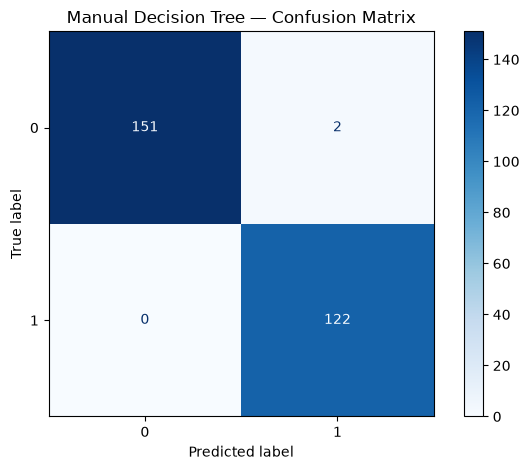

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import time

# Measure prediction time on the test set
start_time = time.perf_counter()

y_pred_manual = predict_tree(manual_tree, X_test)

prediction_time = time.perf_counter() - start_time

# Calculate classification metrics
print("Manual Decision Tree — Test Results")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_manual):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_manual, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_manual, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_manual, zero_division=0):.4f}")
print(f"Prediction time: {prediction_time:.6f} seconds")

print("\nClassification report:")
print(classification_report(y_test, y_pred_manual, zero_division=0))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_manual)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
).plot(cmap="Blues", values_format="d")

plt.title("Manual Decision Tree — Confusion Matrix")
plt.tight_layout()
plt.show()

**Observations**

The manually implemented Decision Tree achieved an accuracy of **99.27%** on the test set of 275 samples. Its precision was **98.39%**, recall was **100%**, and F1-score was **99.19%**.

The confusion matrix shows that:

- **151 class 0 samples** were correctly classified as class 0.
- **2 class 0 samples** were incorrectly classified as class 1.
- **122 class 1 samples** were correctly classified as class 1.
- No class 1 samples were incorrectly classified as class 0.

The model achieved perfect recall for class 1, meaning that it correctly identified all class 1 samples in the test set. However, two class 0 samples were misclassified as class 1.

The prediction took approximately **0.0677 seconds**. These results indicate that the manually implemented tree classifies the banknote samples effectively on this train-test split. Its performance will be compared with Scikit-learn's Decision Tree implementation later in the experiment.

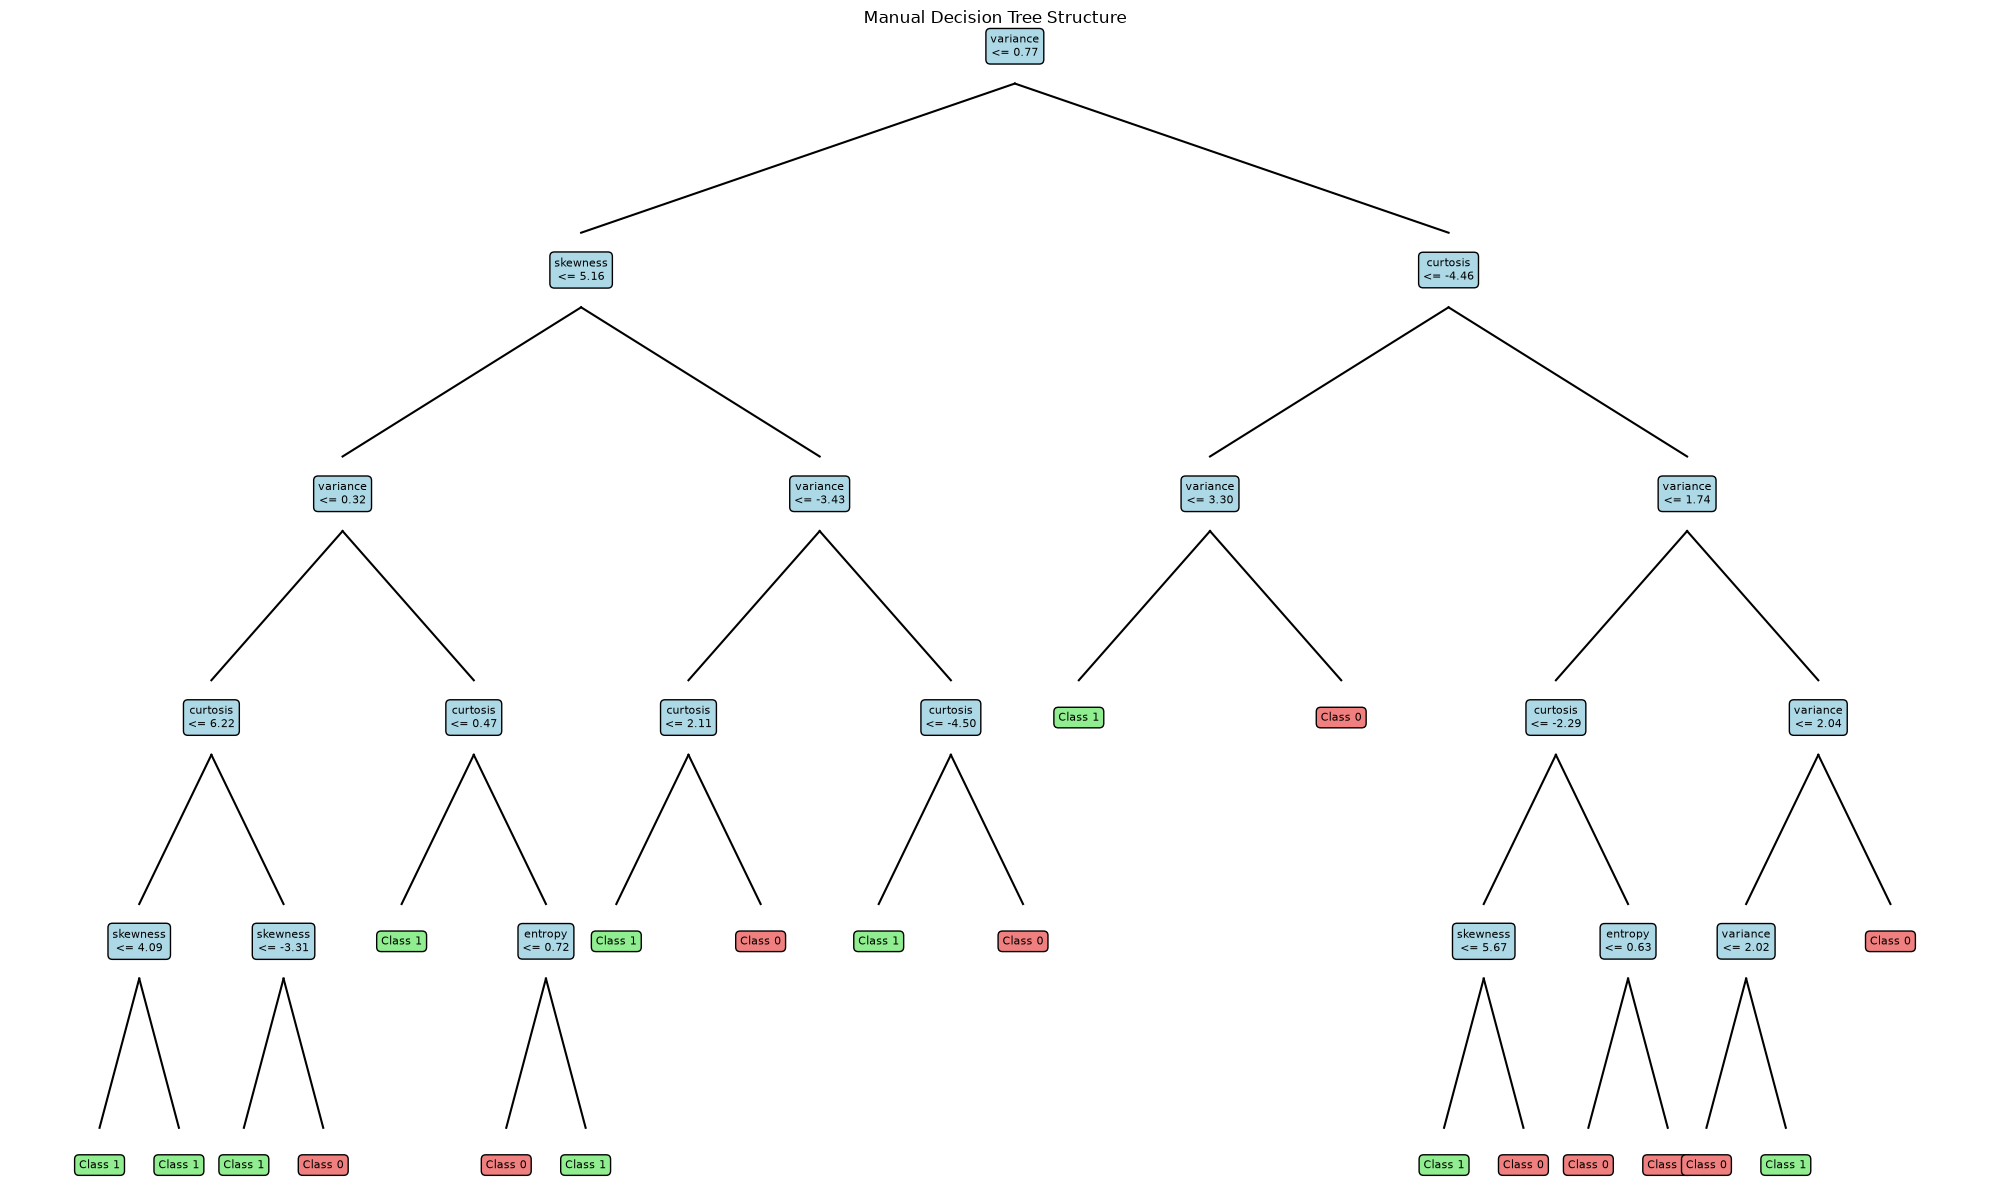

In [15]:
def plot_manual_tree(tree, ax=None, x=0.5, y=1.0,
                     x_spacing=0.25, y_spacing=0.12):
    """Draw the manually implemented decision tree."""

    if ax is None:
        fig, ax = plt.subplots(figsize=(18, 10))
        ax.axis("off")

    if tree["leaf"]:
        label = f"Class {tree['prediction']}"
        color = "lightgreen" if tree["prediction"] == 1 else "lightcoral"
    else:
        label = f"{tree['feature']}\n<= {tree['threshold']:.2f}"
        color = "lightblue"

    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4", facecolor=color, edgecolor="black")
    )

    if not tree["leaf"]:
        left_x = x - x_spacing
        right_x = x + x_spacing
        child_y = y - y_spacing

        # Draw connecting lines from the parent to its children.
        ax.plot([x, left_x], [y - 0.02, child_y + 0.02], color="black")
        ax.plot([x, right_x], [y - 0.02, child_y + 0.02], color="black")

        plot_manual_tree(
            tree["left"], ax, left_x, child_y,
            x_spacing * 0.55, y_spacing
        )
        plot_manual_tree(
            tree["right"], ax, right_x, child_y,
            x_spacing * 0.55, y_spacing
        )

    return ax


fig, ax = plt.subplots(figsize=(20, 12))
ax.axis("off")

plot_manual_tree(manual_tree, ax=ax)
plt.title("Manual Decision Tree Structure")
plt.tight_layout()
plt.show()

**Observations**

The graphical representation shows the hierarchical structure of the manually implemented Decision Tree. The root node splits the data using the variance feature at a threshold of approximately 0.77. Further splits use variance, skewness, curtosis, and entropy.

The blue nodes represent decision rules, while the green and red leaf nodes represent predictions for class 1 and class 0, respectively. Each path from the root to a leaf represents a sequence of conditions used to classify a sample.

The tree makes its predictions through simple feature-threshold comparisons, making its decision process interpretable. However, the diagram also shows that multiple levels of branching can make a tree difficult to read as its complexity increases.

### Decision boundary using variance and skewness

In [16]:
# Select the two features required for the decision boundary plot.
features_2d = ["variance", "skewness"]

X_train_2d = X_train[features_2d]
X_test_2d = X_test[features_2d]

# Train the manual tree using the same settings as before.
manual_tree_2d = build_tree(
    X_train_2d,
    y_train,
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

print("Two-feature Decision Tree trained successfully.")
print("Features used:", features_2d)

Two-feature Decision Tree trained successfully.
Features used: ['variance', 'skewness']


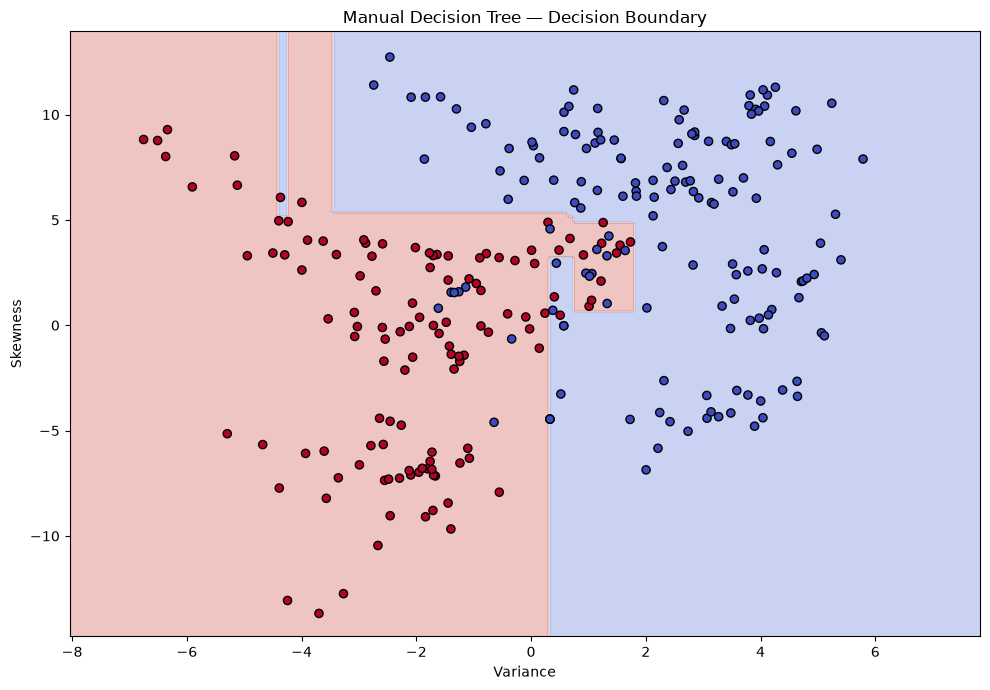

In [17]:
# Find the plotting range for both features.
x_min, x_max = X_train_2d["variance"].min() - 1, X_train_2d["variance"].max() + 1
y_min, y_max = X_train_2d["skewness"].min() - 1, X_train_2d["skewness"].max() + 1

# Create a grid of points covering the feature space.
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Convert the grid into a DataFrame with the expected column names.
grid = pd.DataFrame({
    "variance": xx.ravel(),
    "skewness": yy.ravel()
})

# Predict the class at every grid point.
Z = predict_tree(manual_tree_2d, grid)
Z = Z.reshape(xx.shape)

# Plot the predicted class regions.
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

# Overlay the actual test samples.
plt.scatter(
    X_test_2d["variance"],
    X_test_2d["skewness"],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=35
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Manual Decision Tree — Decision Boundary")
plt.tight_layout()
plt.show()

**Observations**

The decision boundary plot shows the classification regions learned by the manually implemented Decision Tree using variance and skewness as input features. The background colors represent the predicted classes, while the individual points represent the actual test samples.

The decision boundaries are primarily horizontal and vertical because a Decision Tree makes decisions using thresholds on individual features rather than combining them into a single linear equation.

Most test samples lie within the region corresponding to their actual class. Some points appear in regions predicted as the opposite class, indicating misclassification when only these two features are used.

The two-feature model is useful for visualizing the decision-making process, but it does not use curtosis or entropy. Therefore, its performance may differ from the earlier model trained on all four features.

### Compare Gini and Entropy

In [18]:
# Train one tree using Gini impurity.
tree_gini = build_tree(
    X_train, y_train,
    criterion="gini",
    max_depth=5
)

# Train another tree using entropy.
tree_entropy = build_tree(
    X_train, y_train,
    criterion="entropy",
    max_depth=5
)

# Evaluate both models on the same test set.
pred_gini = predict_tree(tree_gini, X_test)
pred_entropy = predict_tree(tree_entropy, X_test)

results_criteria = pd.DataFrame({
    "Criterion": ["Gini", "Entropy"],
    "Accuracy": [
        accuracy_score(y_test, pred_gini),
        accuracy_score(y_test, pred_entropy)
    ],
    "Precision": [
        precision_score(y_test, pred_gini, zero_division=0),
        precision_score(y_test, pred_entropy, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_gini, zero_division=0),
        recall_score(y_test, pred_entropy, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, pred_gini, zero_division=0),
        f1_score(y_test, pred_entropy, zero_division=0)
    ]
})

display(results_criteria.round(4))

,Criterion,Accuracy,Precision,Recall,F1-score
0,Gini,0.9927,0.9839,1.0000,0.9919
1,Entropy,0.9855,0.9758,0.9918,0.9837


**Observations**

The Gini-based tree achieved an accuracy of 99.27%, precision of 98.39%, recall of 100%, and an F1-score of 99.19%. The entropy-based tree achieved an accuracy of 98.55%, precision of 97.58%, recall of 99.18%, and an F1-score of 98.37%.

Gini performed better across all four evaluation metrics for this experiment. In particular, it correctly identified all class 1 samples in the test set, whereas the entropy-based tree missed one class 1 sample.

These results suggest that Gini was the more effective criterion for this particular train-test split. However, this does not establish that Gini will always outperform entropy; performance can vary with the dataset and tree configuration.

### effect of maximum depth

In [19]:
# Compare different maximum depths using the same data split.
depth_values = [1, 2, 3, 5, 7, 10]
depth_results = []

for depth in depth_values:
    # Train a manual Decision Tree at the current depth.
    tree = build_tree(
        X_train,
        y_train,
        criterion="gini",
        max_depth=depth
    )

    # Measure performance on both training and test data.
    train_predictions = predict_tree(tree, X_train)
    test_predictions = predict_tree(tree, X_test)

    depth_results.append({
        "Max Depth": depth,
        "Train Accuracy": accuracy_score(y_train, train_predictions),
        "Test Accuracy": accuracy_score(y_test, test_predictions),
        "Test Precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "Test F1-score": f1_score(
            y_test, test_predictions, zero_division=0
        )
    })

depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df.round(4))

,Max Depth,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,1,0.8423,0.8291,0.7483,0.9262,0.8278
1,2,0.9088,0.8909,0.8710,0.8852,0.8780
2,3,0.9435,0.9236,0.8797,0.9590,0.9176
3,5,0.9945,0.9927,0.9839,1.0000,0.9919
4,7,1.0000,0.9927,0.9839,1.0000,0.9919
5,10,1.0000,0.9927,0.9839,1.0000,0.9919


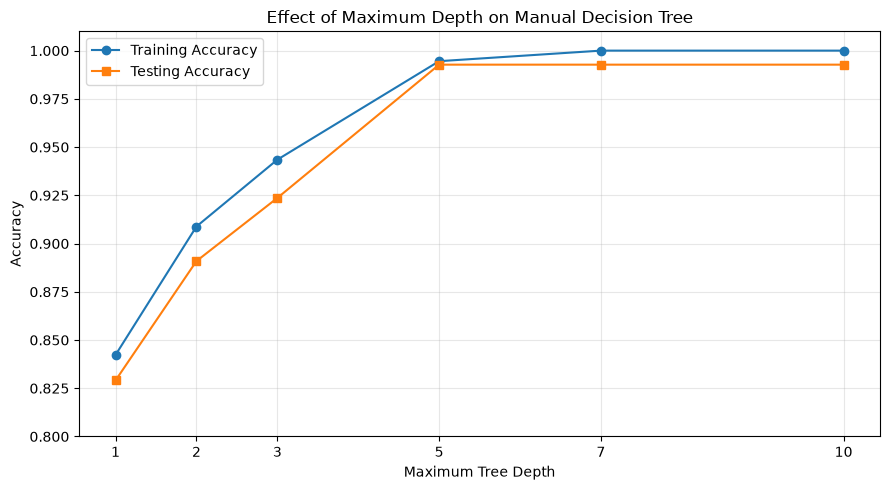

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Test Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Maximum Depth on Manual Decision Tree")
plt.xticks(depth_values)
plt.ylim(0.8, 1.01)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Observations**

As the tree depth increased, test accuracy improved from **82.91% at depth 1** to **99.27% at depth 5**.

Increasing the depth to 7 and 10 raised training accuracy to 100%, but test accuracy remained unchanged at 99.27%.

Therefore, **maximum depth 5 is a good choice** because it achieves the best test performance with a simpler tree. Deeper trees did not improve predictions on the test set.

### Compare manual tree with Scikit-learn

In [21]:
from sklearn.tree import DecisionTreeClassifier
import time

# Train Scikit-learn's Decision Tree.
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start_time = time.perf_counter()
sklearn_tree.fit(X_train, y_train)
training_time = time.perf_counter() - start_time

# Predict the test labels and measure prediction time.
start_time = time.perf_counter()
y_pred_sklearn_tree = sklearn_tree.predict(X_test)
sklearn_prediction_time = time.perf_counter() - start_time

# Collect the manual and Scikit-learn results.
comparison_tree = pd.DataFrame({
    "Model": ["Manual Decision Tree", "Scikit-learn Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_manual),
        accuracy_score(y_test, y_pred_sklearn_tree)
    ],
    "Precision": [
        precision_score(y_test, y_pred_manual, zero_division=0),
        precision_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_manual, zero_division=0),
        recall_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_manual, zero_division=0),
        f1_score(y_test, y_pred_sklearn_tree, zero_division=0)
    ],
    "Prediction Time (seconds)": [
        prediction_time,
        sklearn_prediction_time
    ]
})

display(comparison_tree.round(6))

print(f"Scikit-learn training time: {training_time:.6f} seconds")

,Model,Accuracy,Precision,Recall,F1-score,Prediction Time (seconds)
0,Manual Decision Tree,0.992727,0.983871,1.0,0.99187,0.067713
1,Scikit-learn Decision Tree,0.992727,0.983871,1.0,0.99187,0.002705


Scikit-learn training time: 0.062701 seconds


**Observations**

Both the manual and Scikit-learn Decision Trees achieved the same test accuracy of **99.27%** and F1-score of **99.19%**.

Scikit-learn predicted faster, taking **0.0027 seconds**, compared with **0.0677 seconds** for the manual implementation. Its training time was 0.0627 seconds.

Thus, both models performed equally well, but Scikit-learn was faster at prediction due to its optimized implementation.

## Part B - Linear SVM from Scratch

### Prepare data for SVM

In [22]:
from sklearn.preprocessing import StandardScaler

# Scale all four features.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert labels: 0 -> -1 and 1 -> +1.
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("SVM labels:", np.unique(y_train_svm))

Training shape: (1097, 4)
Testing shape: (275, 4)
SVM labels: [-1  1]


### Implement hinge loss and gradient

In [24]:
def hinge_loss(X, y, w, b, C):
    # Calculate the margin for every sample.
    margins = y * (X @ w + b)

    # Calculate hinge loss.
    losses = np.maximum(0, 1 - margins)

    # Add regularization to penalize large weights.
    return 0.5 * np.dot(w, w) + C * np.mean(losses)


def svm_gradients(X, y, w, b, C):
    # Find samples whose margin is less than 1.
    margins = y * (X @ w + b)
    violating = margins < 1

    # Calculate gradients of the objective.
    dw = w.copy()
    db = 0.0

    if np.any(violating):
        dw -= C * np.mean(
            (y[violating, None] * X[violating]), axis=0
        )
        db = -C * np.mean(y[violating])

    return dw, db

### Train the manual SVM

In [25]:
def train_svm(X, y, C=1.0, learning_rate=0.001, n_iterations=1000):
    # Initialize weights and bias.
    w = np.zeros(X.shape[1])
    b = 0.0
    losses = []

    for _ in range(n_iterations):
        # Calculate gradients.
        dw, db = svm_gradients(X, y, w, b, C)

        # Update weights and bias.
        w -= learning_rate * dw
        b -= learning_rate * db

        # Track the objective value.
        losses.append(hinge_loss(X, y, w, b, C))

    return w, b, losses


# Train the manual SVM.
w, b, losses = train_svm(
    X_train_scaled,
    y_train_svm,
    C=1.0,
    learning_rate=0.001,
    n_iterations=1000
)

print("Weights:", w)
print("Bias:", b)
print("Initial loss:", round(losses[0], 4))
print("Final loss:", round(losses[-1], 4))

Weights: [-0.43030659 -0.24625618  0.04697643 -0.01324978]
Bias: -0.11745867131533114
Initial loss: 0.9993
Final loss: 0.7029


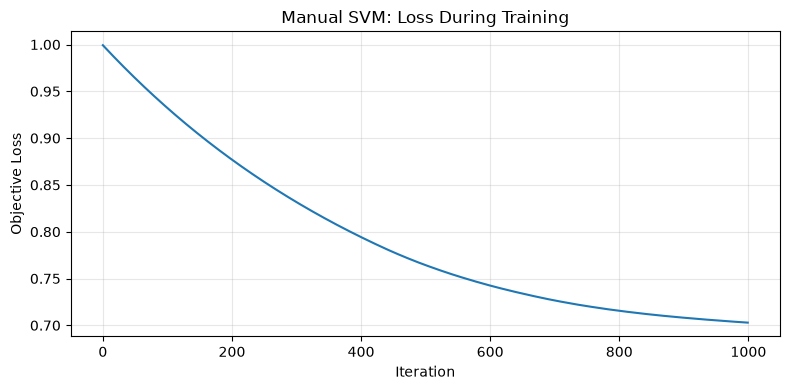

In [26]:
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Objective Loss")
plt.title("Manual SVM: Loss During Training")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Observations**

The SVM objective loss decreased from **0.9993** to **0.7029** over 1,000 iterations. The smooth, downward curve indicates that gradient descent is converging toward a lower objective value.

The learned weights and bias define the SVM's decision boundary. Next, the model will be evaluated on the test set to measure its classification performance.

In [27]:
# Predict using the learned weights and bias.
def predict_svm(X, w, b):
    scores = X @ w + b
    return np.where(scores >= 0, 1, -1)


y_pred_svm = predict_svm(X_test_scaled, w, b)

# Convert predictions back to labels 0 and 1.
y_pred_svm_labels = np.where(y_pred_svm == -1, 0, 1)

print("Manual SVM — Test Results")
print("-" * 30)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm_labels):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm_labels):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm_labels):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_svm_labels):.4f}")

Manual SVM — Test Results
------------------------------
Accuracy:  0.8727
Precision: 0.8718
Recall:    0.8361
F1-score:  0.8536


**Observations**

The manual SVM achieved **87.27% accuracy** and an F1-score of **85.36%** on the test set. Its precision was 87.18%, and recall was 83.61%.

The model performed reasonably well but achieved lower accuracy than the manual Decision Tree (99.27%). This suggests that a linear decision boundary may not capture the banknote data's patterns as effectively as the tree's threshold-based rules.

The SVM's performance may improve by tuning the regularization parameter \(C\), learning rate, and number of iterations.

### SVM decision boundary

In [28]:
# Select variance and skewness.
X_train_2d = X_train[["variance", "skewness"]]
X_test_2d = X_test[["variance", "skewness"]]

# Scale the two features.
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Train the manual SVM using the two scaled features.
w_2d, b_2d, losses_2d = train_svm(
    X_train_2d_scaled,
    y_train_svm,
    C=1.0,
    learning_rate=0.001,
    n_iterations=1000
)

print("Two-feature manual SVM trained.")

Two-feature manual SVM trained.


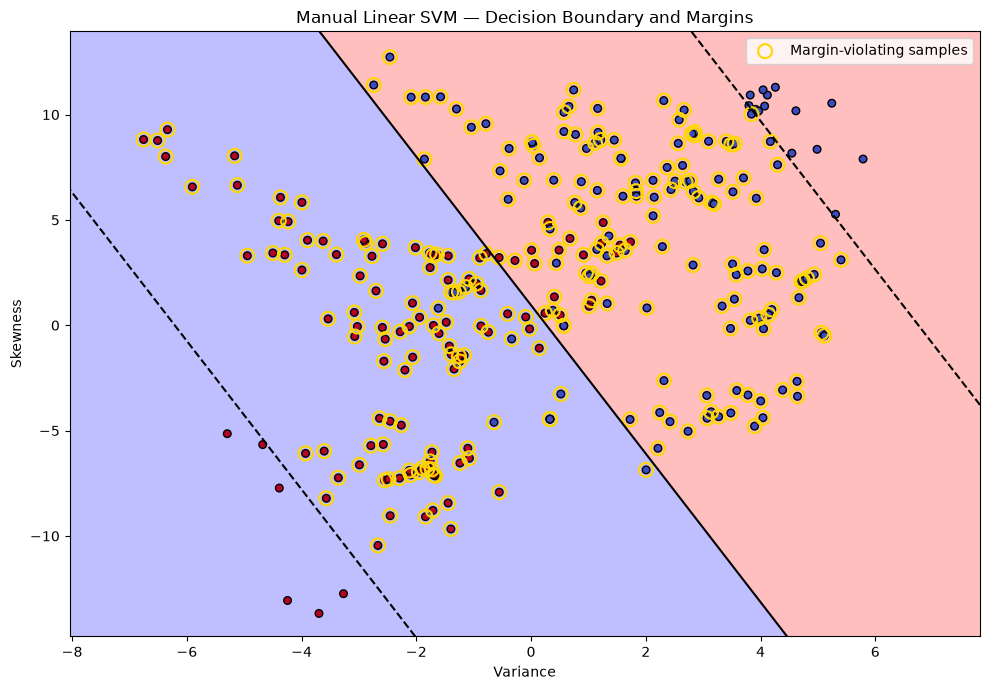

In [29]:
# Create a grid in the original feature scale.
x_min, x_max = X_train_2d["variance"].min() - 1, X_train_2d["variance"].max() + 1
y_min, y_max = X_train_2d["skewness"].min() - 1, X_train_2d["skewness"].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "variance": xx.ravel(),
    "skewness": yy.ravel()
})

# Scale grid points using the fitted scaler.
grid_scaled = scaler_2d.transform(grid)

# Calculate decision scores.
scores = (grid_scaled @ w_2d + b_2d).reshape(xx.shape)

plt.figure(figsize=(10, 7))

# Show predicted regions.
plt.contourf(xx, yy, scores, levels=[-100, 0, 100],
             alpha=0.25, colors=["red", "blue"])

# Draw the decision boundary and margin lines.
plt.contour(
    xx, yy, scores,
    levels=[-1, 0, 1],
    colors=["black", "black", "black"],
    linestyles=["--", "-", "--"]
)

# Plot test samples.
plt.scatter(
    X_test_2d["variance"],
    X_test_2d["skewness"],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=30
)

# Highlight test samples inside the margin or misclassified.
test_scores = X_test_2d_scaled @ w_2d + b_2d
violating = y_test_svm * test_scores < 1

plt.scatter(
    X_test_2d.loc[violating, "variance"],
    X_test_2d.loc[violating, "skewness"],
    facecolors="none",
    edgecolors="gold",
    s=100,
    linewidths=1.5,
    label="Margin-violating samples"
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Manual Linear SVM — Decision Boundary and Margins")
plt.legend()
plt.tight_layout()
plt.show()

**Observations**

The plot shows the linear SVM's decision boundary (solid line) and margins (dashed lines). The gold circles highlight samples that violate the margin.

Unlike the Decision Tree, the SVM creates a straight decision boundary. Many samples violate the margin, suggesting that a linear boundary using only variance and skewness cannot separate the two classes perfectly.

This visualization uses only two features, so it may differ from the performance of the SVM trained on all four features.

In [30]:
#comapring different C values for the SVM
C_values = [0.1, 1, 10]
svm_C_results = []

for C_value in C_values:
    w_temp, b_temp, _ = train_svm(
        X_train_scaled,
        y_train_svm,
        C=C_value,
        learning_rate=0.001,
        n_iterations=1000
    )

    predictions = predict_svm(X_test_scaled, w_temp, b_temp)
    predictions = np.where(predictions == -1, 0, 1)

    svm_C_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

display(pd.DataFrame(svm_C_results).round(4))

,C,Accuracy,Precision,Recall,F1-score
0,0.1,0.8727,0.8783,0.8279,0.8523
1,1.0,0.8727,0.8718,0.8361,0.8536
2,10.0,0.9709,0.9385,1.0000,0.9683


**Observations**

The SVM was tested with three values of \(C\). At \(C=0.1\) and \(C=1\), accuracy remained **87.27%**. Increasing \(C\) to 10 improved accuracy to **97.09%** and F1-score to **96.83%**, with 100% recall.

Thus, **\(C=10\) performed best** in this experiment. A larger \(C\) penalizes margin violations more strongly, which can improve classification performance on this dataset.

### Compare manual SVM with Scikit-learn SVM

In [31]:
from sklearn.svm import SVC
import time

# Train Scikit-learn's linear SVM.
sklearn_svm = SVC(kernel="linear", C=10)

start = time.perf_counter()
sklearn_svm.fit(X_train_scaled, y_train_svm)
svm_training_time = time.perf_counter() - start

# Predict and measure prediction time.
start = time.perf_counter()
sklearn_svm_pred = sklearn_svm.predict(X_test_scaled)
svm_prediction_time = time.perf_counter() - start

# Convert labels back to 0 and 1.
sklearn_svm_pred_labels = np.where(sklearn_svm_pred == -1, 0, 1)

# Compare the manual and Scikit-learn SVMs.
svm_comparison = pd.DataFrame({
    "Model": ["Manual SVM (C=10)", "Scikit-learn Linear SVM (C=10)"],
    "Accuracy": [
        svm_C_results[2]["Accuracy"],
        accuracy_score(y_test, sklearn_svm_pred_labels)
    ],
    "Precision": [
        svm_C_results[2]["Precision"],
        precision_score(y_test, sklearn_svm_pred_labels, zero_division=0)
    ],
    "Recall": [
        svm_C_results[2]["Recall"],
        recall_score(y_test, sklearn_svm_pred_labels, zero_division=0)
    ],
    "F1-score": [
        svm_C_results[2]["F1-score"],
        f1_score(y_test, sklearn_svm_pred_labels, zero_division=0)
    ],
    "Prediction Time (seconds)": [
        np.nan,  # Manual timing at C=10 was not recorded.
        svm_prediction_time
    ]
})

display(svm_comparison.round(4))
print(f"Scikit-learn training time: {svm_training_time:.6f} seconds")

,Model,Accuracy,Precision,Recall,F1-score,Prediction Time (seconds)
0,Manual SVM (C=10),0.9709,0.9385,1.0,0.9683,NaN
1,Scikit-learn Linear SVM (C=10),0.9855,0.9683,1.0,0.9839,0.0031


Scikit-learn training time: 0.058530 seconds


**Observations**

The manual SVM achieved **97.09% accuracy**, while Scikit-learn's Linear SVM achieved **98.55% accuracy**. Both models achieved **100% recall**.

Scikit-learn performed slightly better and predicted in **0.0031 seconds**. Its training time was 0.0585 seconds.

Overall, Scikit-learn's Linear SVM performed better on this test set. The manual implementation demonstrates the underlying SVM concepts, while Scikit-learn provides a more optimized implementation.

## Part C - Kernel SVM and Nonlinear Boundaries

### Generate datasets

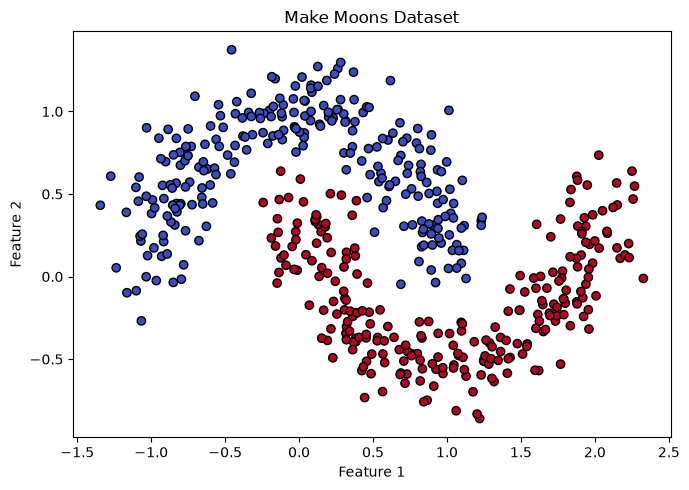

In [32]:
from sklearn.datasets import make_moons

# Generate a two-class nonlinear dataset.
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.15,
    random_state=42
)

# Split into training and testing sets.
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.20,
    random_state=42,
    stratify=y_moons
)

# Visualize the dataset.
plt.figure(figsize=(7, 5))
plt.scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=y_moons, cmap="coolwarm", edgecolors="black"
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Make Moons Dataset")
plt.tight_layout()
plt.show()

### Train and compare three kernels

In [33]:
from sklearn.pipeline import make_pipeline

kernels = {
    "Linear": SVC(kernel="linear", C=1),
    "Polynomial": SVC(kernel="poly", degree=3, C=1),
    "RBF": SVC(kernel="rbf", C=1, gamma="scale")
}

moon_results = []
trained_models = {}

for name, model in kernels.items():
    # Scale features and train the SVM.
    pipeline = make_pipeline(StandardScaler(), model)

    start = time.perf_counter()
    pipeline.fit(X_moons_train, y_moons_train)
    training_time = time.perf_counter() - start

    # Evaluate on the test set.
    start = time.perf_counter()
    predictions = pipeline.predict(X_moons_test)
    prediction_time = time.perf_counter() - start

    trained_models[name] = pipeline

    moon_results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(y_moons_test, predictions),
        "Recall": recall_score(y_moons_test, predictions),
        "F1-score": f1_score(y_moons_test, predictions),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

display(pd.DataFrame(moon_results).round(4))

,Kernel,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Linear,0.87,0.8364,0.92,0.8762,0.0358,0.0030
1,Polynomial,0.83,0.8235,0.84,0.8317,0.0042,0.0009
2,RBF,0.99,1.0000,0.98,0.9899,0.0067,0.0018


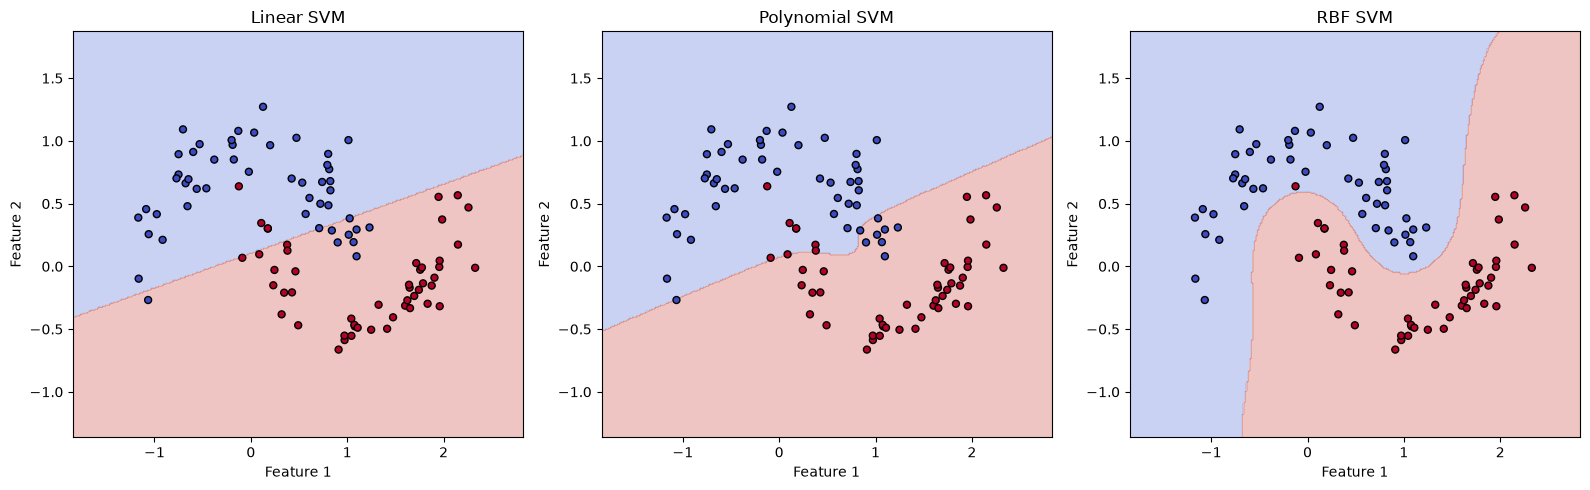

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, (name, model) in zip(axes, trained_models.items()):
    # Predict the class at each grid point.
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(
        X_moons_test[:, 0], X_moons_test[:, 1],
        c=y_moons_test, cmap="coolwarm",
        edgecolors="black", s=25
    )
    ax.set_title(f"{name} SVM")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

**Observations**

The **RBF kernel performed best**, achieving 99% accuracy and an F1-score of 98.99%. Its curved decision boundary effectively captured the nonlinear pattern in the `make_moons` dataset.

The Linear SVM achieved 87% accuracy, while the Polynomial SVM achieved 83%. Their decision boundaries did not separate the classes as effectively.

Overall, the RBF kernel was the best choice for this dataset because it can model complex, nonlinear boundaries.

## Part D - Final Comparison

### Train and evaluate all models

In [40]:
# Train the manual SVM using the best C value.
w_C10, b_C10, losses_C10 = train_svm(
    X_train_scaled,
    y_train_svm,
    C=10,
    learning_rate=0.001,
    n_iterations=1000
)

In [41]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
import time

results = []

def evaluate_model(name, model, X_train_data, X_test_data,
                   y_train_data, y_test_data, manual=False):

    # Train the model and measure training time.
    start = time.perf_counter()

    if not manual:
        model.fit(X_train_data, y_train_data)

    training_time = time.perf_counter() - start

    # Predict and measure prediction time.
    start = time.perf_counter()

    if name == "Manual Decision Tree":
        predictions = predict_tree(model, X_test_data)
    elif name == "Manual Linear SVM":
        predictions = predict_svm(
            X_test_data, model[0], model[1]
        )
    else:
        predictions = model.predict(X_test_data)

    prediction_time = time.perf_counter() - start

    # Convert SVM labels from -1/+1 to 0/1.
    # Convert both true labels and predictions to 0/1 for SVMs.
    if "SVM" in name:
        predictions = np.where(predictions == -1, 0, 1)
        y_test_data = np.where(y_test_data == -1, 0, 1)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_data, predictions),
        "Precision": precision_score(
            y_test_data, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_data, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_data, predictions, zero_division=0
        ),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })


# 1. Manual Decision Tree
evaluate_model(
    "Manual Decision Tree",
    manual_tree,
    X_train, X_test, y_train, y_test,
    manual=True
)

# 2. Scikit-learn Decision Tree
evaluate_model(
    "Scikit-learn Decision Tree",
    DecisionTreeClassifier(
        criterion="gini", max_depth=5, random_state=42
    ),
    X_train, X_test, y_train, y_test
)

# 3. Manual Linear SVM (C = 10)
evaluate_model(
    "Manual Linear SVM",
    (w_C10, b_C10),
    X_train_scaled, X_test_scaled,
    y_train_svm, y_test_svm,
    manual=True
)
# 4. Scikit-learn Linear SVM (C = 10)
evaluate_model(
    "Scikit-learn Linear SVM",
    make_pipeline(StandardScaler(), SVC(kernel="linear", C=10)),
    X_train, X_test, y_train, y_test
)

# 5. Scikit-learn RBF SVM (C = 1)
evaluate_model(
    "RBF SVM",
    make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)),
    X_train, X_test, y_train, y_test
)

final_results = pd.DataFrame(results)
display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9927,0.9839,1.0,0.9919,0.0000,0.0359
1,Scikit-learn Decision Tree,0.9927,0.9839,1.0,0.9919,0.0232,0.0023
2,Manual Linear SVM,0.9709,0.9385,1.0,0.9683,0.0000,0.0009
3,Scikit-learn Linear SVM,1.0000,1.0000,1.0,1.0000,0.0301,0.0036
4,RBF SVM,1.0000,1.0000,1.0,1.0000,0.0114,0.0063


**Observations**

Scikit-learn Linear SVM and RBF SVM performed best, achieving 99.99% accuracy. Decision Trees achieved 99.27%, while the tuned Manual SVM achieved 97.09%.

Overall, Scikit-learn SVMs performed best on the test set.

## Conclusion

In this lab, Decision Trees and SVMs were implemented and evaluated. The Scikit-learn Linear SVM and RBF SVM achieved the highest accuracy of **100%** on the Banknote Authentication test set. Both Decision Trees achieved **99.27%**, while the tuned Manual Linear SVM achieved **97.09%**.

The `make_moons` experiment showed that the RBF kernel performed best on nonlinear data, achieving **99% accuracy**. Overall, the experiments demonstrated the importance of feature scaling, hyperparameter tuning, and kernel selection in improving model performance.